In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

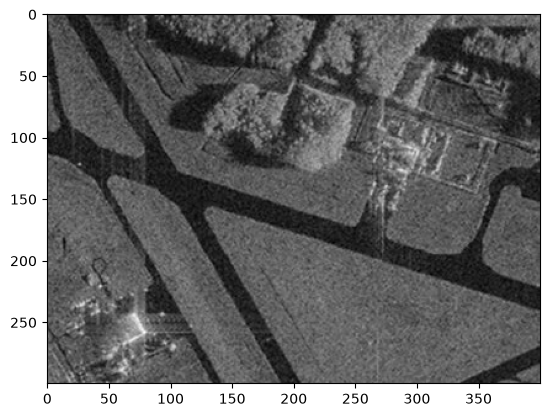

In [2]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")

### 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.

In [3]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])

    if abs(av_val - img[point]) <= T:
        return True

    return False

In [14]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r + 1, j-r: j+r+1].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        #print(count)
        mask += local_mask

    return mask*255

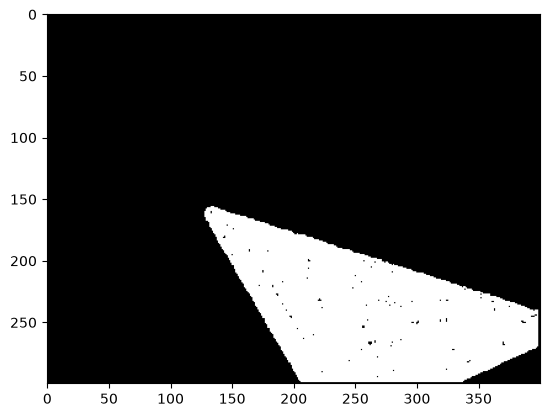

In [15]:
seed_point = (200,225)
mask = region_growing(image_gray,seed_point,homo_average,1, 25)
plt.imshow(mask, cmap="gray")

##### Подобранные величины: точка (200, 225) и порог Т = 25

### 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.

In [16]:
def homo_max(img, mask, point, T):
    max_val = float(max(img[mask > 0]))

    if abs(max_val - img[point]) <= T:
        return True

    return False

In [17]:
seed_point = (200,225)
mask_1 = region_growing(image_gray,seed_point,homo_max,1, 25)

In [18]:
seed_point = (200,225)
mask_2 = region_growing(image_gray,seed_point,homo_max,1, 75)

In [19]:
seed_point = (225,225)
mask_3 = region_growing(image_gray,seed_point,homo_max,1, 25)

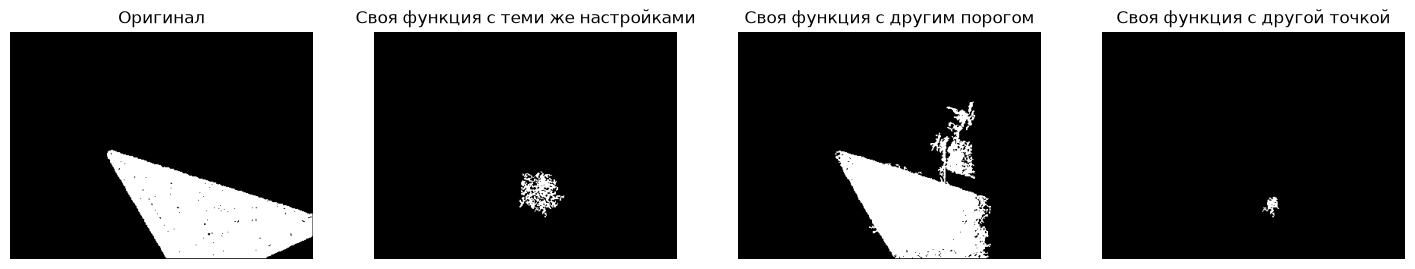

In [20]:
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
ax[0].imshow(mask, cmap='gray');   ax[0].set_title('Оригинал')
ax[1].imshow(mask_1, cmap='gray'); ax[1].set_title('Своя функция с теми же настройками')
ax[2].imshow(mask_2, cmap='gray'); ax[2].set_title('Своя функция с другим порогом')
ax[3].imshow(mask_3, cmap='gray'); ax[3].set_title('Своя функция с другой точкой')
for a in ax: a.axis('off')
plt.show()

##### Вывод: вычисление разницы между средней яркостью и яркостью в точке в качестве критерия работает лучше, чем разница между максимумом и яркостью в точке

### 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

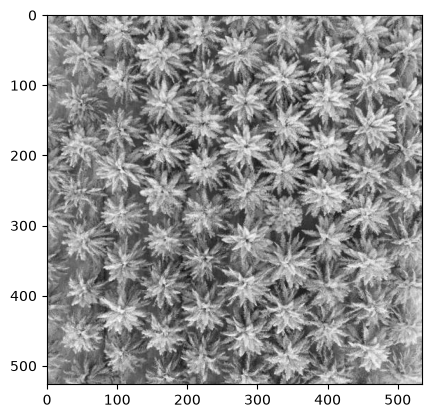

In [21]:
image = cv2.imread('palm_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")

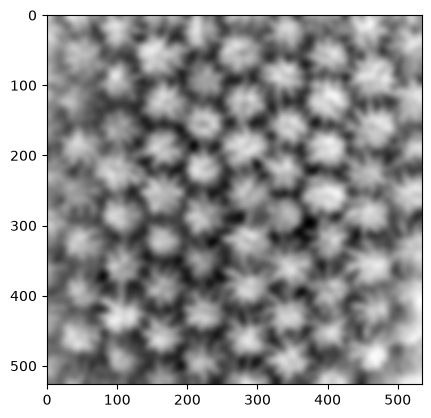

In [43]:
image_gray = cv2.GaussianBlur(image_gray, (17, 17), 0)
plt.imshow(image_gray, cmap='gray')

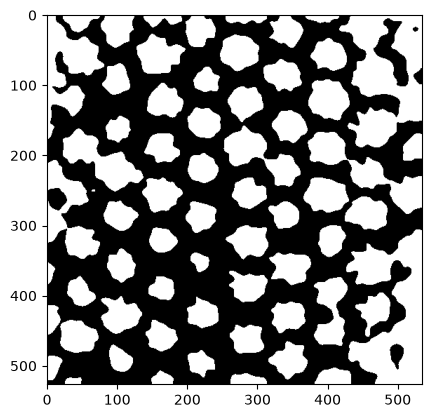

In [44]:
ret, thresh = cv2.threshold(image_gray,0,255, cv2.THRESH_OTSU)
plt.imshow(thresh, cmap="gray")

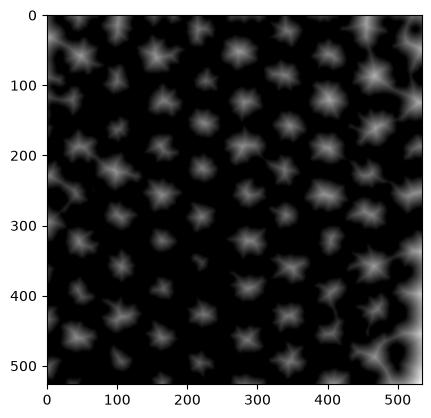

In [45]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)
plt.imshow(dist, cmap="gray")

In [46]:
best_delta = 10000000000000000
best_tree_cnt = 0
best_coef = 0.1
for coef in [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7]:
    ret, sure_fg = cv2.threshold(dist, coef * dist.max(), 255, cv2.THRESH_BINARY)
    sure_fg_1 = sure_fg.astype(np.uint8)
    ret, markers = cv2.connectedComponents(sure_fg_1)
    markers_1 = cv2.watershed(image, markers)
    tree_cnt = markers_1.max() - 1
    print(f"coef={coef} -> семян: {ret - 1}, деревьев: {tree_cnt}")
    delta = abs(tree_cnt - 69)
    if best_delta >= delta:
        best_delta = delta
        best_tree_cnt = tree_cnt
        best_coef = coef

coef=0.05 -> семян: 67, деревьев: 66
coef=0.1 -> семян: 69, деревьев: 68
coef=0.15 -> семян: 75, деревьев: 74
coef=0.2 -> семян: 76, деревьев: 75
coef=0.25 -> семян: 79, деревьев: 78
coef=0.3 -> семян: 76, деревьев: 75
coef=0.35 -> семян: 75, деревьев: 74
coef=0.4 -> семян: 66, деревьев: 65
coef=0.45 -> семян: 53, деревьев: 52
coef=0.5 -> семян: 30, деревьев: 29
coef=0.55 -> семян: 22, деревьев: 20
coef=0.6 -> семян: 11, деревьев: 10
coef=0.65 -> семян: 7, деревьев: 6
coef=0.7 -> семян: 4, деревьев: 3


In [47]:
print(f"Лучший коэффициент: {best_coef}, кол-во деревьев: {best_tree_cnt}")

Лучший коэффициент: 0.1, кол-во деревьев: 68


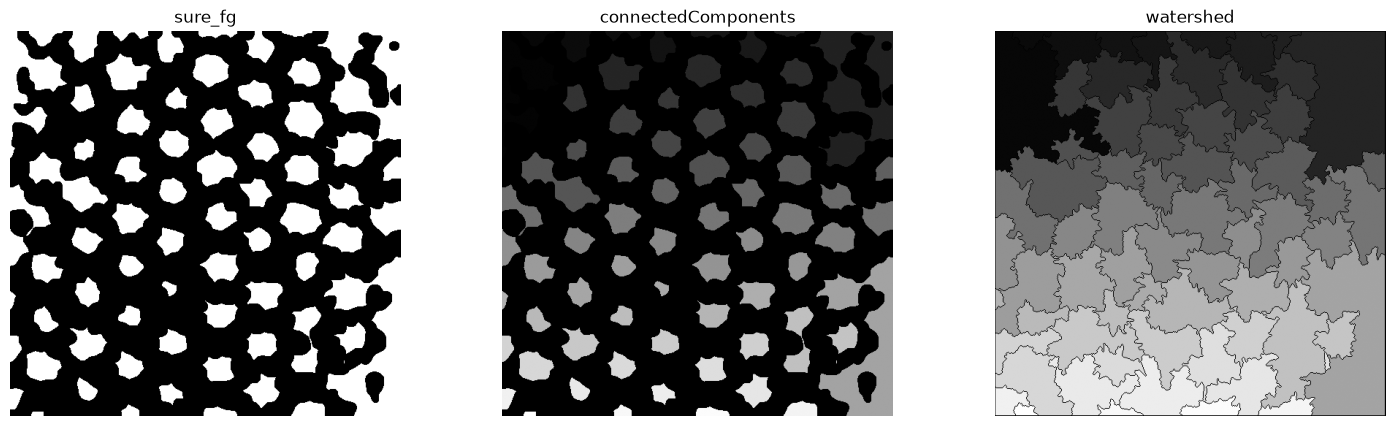

In [48]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ret, sure_fg = cv2.threshold(dist, best_coef * dist.max(), 255, cv2.THRESH_BINARY)
ax[0].imshow(sure_fg, cmap="gray"); ax[0].set_title('sure_fg')

sure_fg = sure_fg.astype(np.uint8)
ret, markers = cv2.connectedComponents(sure_fg)
ax[1].imshow(markers, cmap="gray"); ax[1].set_title('connectedComponents')

markers = cv2.watershed(image, markers)
ax[2].imshow(markers, cmap="gray"); ax[2].set_title('watershed')

for a in ax: a.axis('off')
plt.show()